In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
results = pd.read_csv("/content/drive/MyDrive/pendulo_fluido.csv")

In [ ]:
results

,t,theta,L,m,g
0,0.000,0.2030,0.55,0.35,9.78
1,0.090,0.1830,0.55,0.35,9.78
2,0.181,0.1457,0.55,0.35,9.78
3,0.271,0.0896,0.55,0.35,9.78
4,0.362,0.0074,0.55,0.35,9.78
...,...,...,...,...,...
195,17.638,0.0175,0.55,0.35,9.78
196,17.729,0.0183,0.55,0.35,9.78
197,17.819,0.0294,0.55,0.35,9.78
198,17.910,0.0296,0.55,0.35,9.78


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Columnas disponibles: ['t', 'theta', 'L', 'm', 'g']


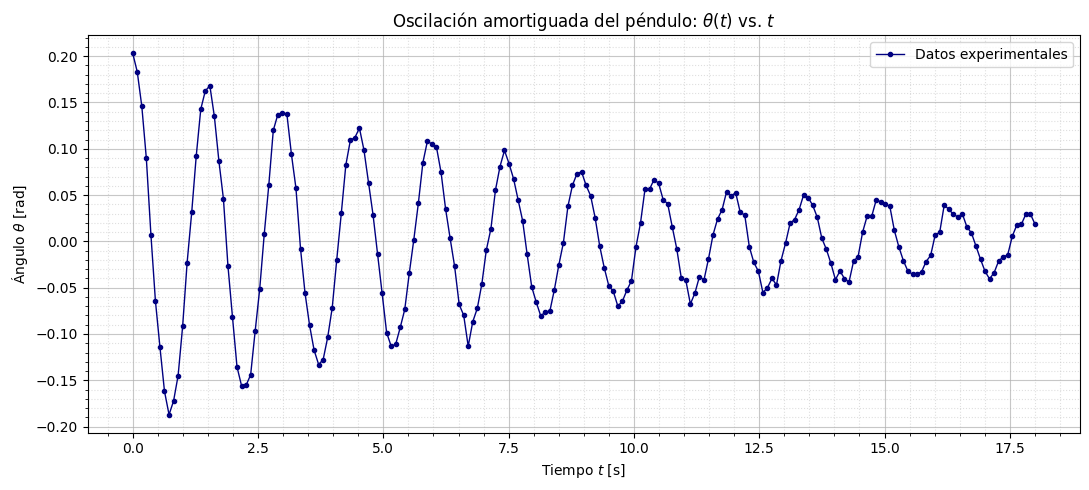

In [ ]:
print("Columnas disponibles:", results.columns.tolist())


t = results['t']
theta = results['theta']


plt.figure(figsize=(11, 5))
plt.plot(t, theta, 'o-', markersize=3, linewidth=1, color='navy', label='Datos experimentales')

plt.title('Oscilación amortiguada del péndulo: $\\theta(t)$ vs. $t$')
plt.xlabel('Tiempo $t$ [s]')
plt.ylabel('Ángulo $\\theta$ [rad]')


plt.minorticks_on()
plt.grid(True, which='major', linestyle='-', alpha=0.7)
plt.grid(True, which='minor', linestyle=':', alpha=0.4)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
##punto 3

from scipy.optimize import curve_fit


def modelo_pendulo(t, theta_0, gamma, omega):
    return theta_0 * np.exp(-gamma * t) * np.cos(omega * t)


theta_0_est =
gamma_est   =
omega_est   =
p0 = [theta_0_est, gamma_est, omega_est]


popt, pcov = curve_fit(
    modelo_pendulo,
    t,
    theta,
    p0=p0,
    bounds=([0, 0, 0], [np.inf, np.inf, np.inf]),
    maxfev=10000
)


theta_0_opt, gamma_opt, omega_opt = popt
perr = np.sqrt(np.diag(pcov))
sigma_theta_0, sigma_gamma, sigma_omega = perr


print("=== Parámetros óptimos e incertidumbres ===")
print(f"theta_0 = {theta_0_opt:.6f} ± {sigma_theta_0:.6f} rad")
print(f"gamma   = {gamma_opt:.6f} ± {sigma_gamma:.6f} s^-1")
print(f"omega   = {omega_opt:.6f} ± {sigma_omega:.6f} rad/s")

=== Parámetros óptimos e incertidumbres ===
theta_0 = 0.199514 ± 0.001632 rad
gamma   = 0.107053 ± 0.001434 s^-1
omega   = 4.214673 ± 0.000975 rad/s


In [ ]:
##punto 4

m = results['m'].iloc[0]


b_exp = 2 * m * gamma_opt
sigma_b = 2 * m * sigma_gamma

print("=== Coeficiente de arrastre experimental ===")
print(f"Masa utilizada: m = {m} kg")
print(f"b_exp = {b_exp:.6f} ± {sigma_b:.6f} kg/s")

=== Coeficiente de arrastre experimental ===
Masa utilizada: m = 0.35 kg
b_exp = 0.074937 ± 0.001004 kg/s


In [ ]:
##punto 5
fluidos_ref = {
    "Aire seco (20°C)": (0.0035, 0.0005),
    "Mezcla hidroalcohólica": (0.0180, 0.0015),
    "Aceite mineral de baja viscosidad": (0.0360, 0.0020),
    "Glicerina diluida al 30%": (0.0750, 0.0030),
    "Solución concentrada de sacarosa": (0.1200, 0.0050),
}

b_min_exp = b_exp - sigma_b
b_max_exp = b_exp + sigma_b

print(f"Valor experimental: b_exp = {b_exp:.6f} ± {sigma_b:.6f} kg/s")
print(f"Intervalo experimental: [{b_min_exp:.6f}, {b_max_exp:.6f}] kg/s\n")

for nombre, (b_ref, sig_ref) in fluidos_ref.items():
    b_min_ref = b_ref - sig_ref
    b_max_ref = b_ref + sig_ref
    solapa = (b_min_exp <= b_max_ref) and (b_max_exp >= b_min_ref)
    diff = abs(b_exp - b_ref)
    print(f"- {nombre}: ref = {b_ref:.4f} ± {sig_ref:.4f} | "
          f"Solapa con margen de error: {'SÍ' if solapa else 'NO'} | "
          f"Diferencia absoluta: {diff:.6f} kg/s")

Valor experimental: b_exp = 0.074937 ± 0.001004 kg/s
Intervalo experimental: [0.073934, 0.075941] kg/s

- Aire seco (20°C): ref = 0.0035 ± 0.0005 | Solapa con margen de error: NO | Diferencia absoluta: 0.071437 kg/s
- Mezcla hidroalcohólica: ref = 0.0180 ± 0.0015 | Solapa con margen de error: NO | Diferencia absoluta: 0.056937 kg/s
- Aceite mineral de baja viscosidad: ref = 0.0360 ± 0.0020 | Solapa con margen de error: NO | Diferencia absoluta: 0.038937 kg/s
- Glicerina diluida al 30%: ref = 0.0750 ± 0.0030 | Solapa con margen de error: SÍ | Diferencia absoluta: 0.000063 kg/s
- Solución concentrada de sacarosa: ref = 0.1200 ± 0.0050 | Solapa con margen de error: NO | Diferencia absoluta: 0.045063 kg/s


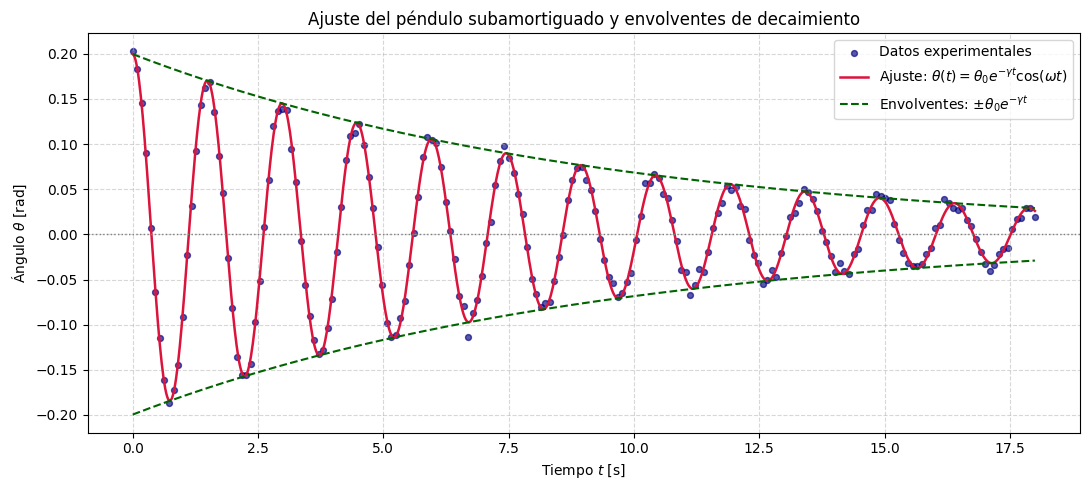

In [ ]:
##punto 6

t_fino = np.linspace(np.min(t), np.max(t), 1000)

theta_ajustado = modelo_pendulo(t_fino, theta_0_opt, gamma_opt, omega_opt)
envolvente_sup = theta_0_opt * np.exp(-gamma_opt * t_fino)
envolvente_inf = -theta_0_opt * np.exp(-gamma_opt * t_fino)

plt.figure(figsize=(11, 5))

plt.scatter(t, theta, color='navy', s=18, alpha=0.65, label='Datos experimentales')

plt.plot(t_fino, theta_ajustado, color='crimson', linewidth=1.8,
         label=r'Ajuste: $\theta(t) = \theta_0 e^{-\gamma t}\cos(\omega t)$')

plt.plot(t_fino, envolvente_sup, color='darkgreen', linestyle='--', linewidth=1.5,
         label=r'Envolventes: $\pm \theta_0 e^{-\gamma t}$')
plt.plot(t_fino, envolvente_inf, color='darkgreen', linestyle='--', linewidth=1.5)

plt.axhline(0, color='gray', linestyle=':', linewidth=1)

plt.title('Ajuste del péndulo subamortiguado y envolventes de decaimiento')
plt.xlabel('Tiempo $t$ [s]')
plt.ylabel('Ángulo $\\theta$ [rad]')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

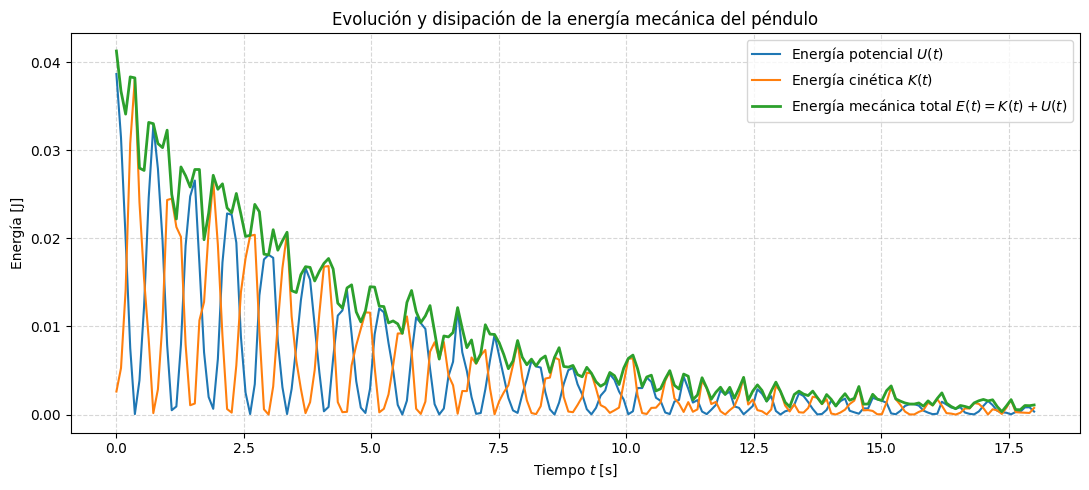

In [ ]:
##punto 7

t = results['t'].to_numpy(dtype=float)
theta = results['theta'].to_numpy(dtype=float)
L = float(results['L'].iloc[0])
m = float(results['m'].iloc[0])

g_exp = 9.78

theta_punto = np.gradient(theta, t)

U = m * g_exp * L * (1.0 - np.cos(theta))
K = 0.5 * m * (L**2) * (theta_punto**2)
E = K + U

plt.figure(figsize=(11, 5))

plt.plot(t, U, label=r'Energía potencial $U(t)$', color='tab:blue', linewidth=1.5)
plt.plot(t, K, label=r'Energía cinética $K(t)$', color='tab:orange', linewidth=1.5)
plt.plot(t, E, label=r'Energía mecánica total $E(t) = K(t) + U(t)$', color='tab:green', linewidth=2.0)

plt.title('Evolución y disipación de la energía mecánica del péndulo')
plt.xlabel('Tiempo $t$ [s]')
plt.ylabel('Energía [J]')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()